In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import logsumexp
from scipy.stats import norm
from scipy.stats import gaussian_kde
import arviz as az
from bayesian_stats_course_tools.analyse import analyse_data
import dynesty

# Week 8 Solutions

# Exercise 1


**Apply LOO-CV, WAIC, DIC, and Bayes factors to the linear and quadratic models from `lectures/data/linear_fits/data_2.txt`**

Questions to answer: 
1. Which model is generally preferred using these parameters?
2. How do the LOO-CV, WAIC, and DIC results change if you change the priors on the slope and intercept, as we did for Bayes factors in Week 6?
3. How do the WAIC, LOO-CV, and DIC `elpd` values compare for the quadratic model? Are they close?

## Bayes factors (nested sampling and Savage-dickey)

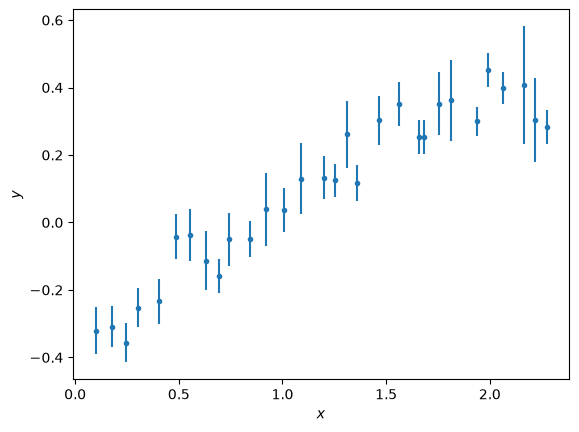

In [2]:
x, y, y_err = np.loadtxt("../lectures/data/linear_fits/data_2.txt", unpack=True)

plt.errorbar(x, y, y_err, fmt=".")
plt.xlabel("$x$")
plt.ylabel("$y$");

In [3]:
def quadratic_model(theta, x):
    a, b, c = theta
    return a*x**2 + b*x + c

def linear_model(theta, x):
    m, b = theta
    return m*x + b

def log_likelihood(theta, model, x, y, y_err):
    mu = model(theta, x)
    return (
        -0.5*np.sum((y - mu)**2/y_err**2)        # Exponent
        - 0.5*np.sum(np.log(2*np.pi*y_err**2))   # Normalisation
    )

In [4]:
def prior_transform(u):
    return 6*u - 3

def run_dynesty(model, n_dim, prior_transform, x, y, y_err, seed):
    sampler = dynesty.NestedSampler(
        loglikelihood=lambda theta: log_likelihood(theta, model, x, y, y_err),
        prior_transform=prior_transform,
        ndim=n_dim,
        nlive=5000,
        rstate=np.random.default_rng(seed),
    )
    sampler.run_nested(print_progress=True)
    return sampler.results
results_linear = run_dynesty(linear_model, 2, prior_transform, x, y, y_err, seed=11)
results_quadratic = run_dynesty(quadratic_model, 3, prior_transform, x, y, y_err, seed=11)

100%|█████████▉| 63501/63502 [00:22<00:00, 2764.40it/s, +5000 | bound: 15 | nc: 1 | ncall: 253349 | eff(%): 27.583 | loglstar: 37.796 | logz: 23.298 +/-  0.074 | dlogz:  0.001 >  5.009]  


In [5]:
samples_q = results_quadratic.samples_equal(rstate=np.random.default_rng(11))

(array([   38.,   490.,  2886., 10282., 20131., 20580., 10565.,  3053.,
          436.,    40.]),
 array([-0.58959432, -0.55842674, -0.52725915, -0.49609157, -0.46492398,
        -0.4337564 , -0.40258881, -0.37142123, -0.34025364, -0.30908606,
        -0.27791847]),
 <BarContainer object of 10 artists>)

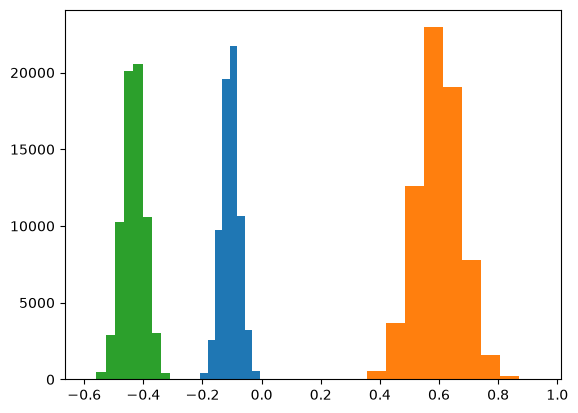

In [13]:
plt.hist(samples_q[:,0])
plt.hist(samples_q[:,1])
plt.hist(samples_q[:,2])

In [ ]:
quadratic_coeff = samples_q[:, 0]          # a in a*x**2 + b*x + c
prior_density_at_zero = 1 / 6              # U(-3, 3)

posterior_density_gauss = norm.pdf(0, loc=quadratic_coeff.mean(), scale=quadratic_coeff.std())

posterior_density_kde = gaussian_kde(quadratic_coeff)(0)[0]

print("Savage-Dickey BF (quad/lin), Gaussian approx:", prior_density_at_zero / posterior_density_gauss)
print("Savage-Dickey BF (quad/lin), KDE:            ", prior_density_at_zero / posterior_density_kde)
print("Nested sampling BF (quad/lin):               ", np.exp(results_quadratic.logz[-1] - results_linear.logz[-1]))

In [ ]:
fig, ax = plt.subplots()
ax.hist(quadratic_coeff, bins=50, density=True, alpha=0.5, label="Posterior samples")

coeff_grid = np.linspace(-0.25, 0.05, 400)
ax.plot(coeff_grid, gaussian_kde(quadratic_coeff)(coeff_grid), color="C0", label="Posterior KDE")
ax.plot(coeff_grid, norm.pdf(coeff_grid, quadratic_coeff.mean(), quadratic_coeff.std()),
        color="C2", ls="--", label="Posterior Gaussian approx")
ax.axhline(prior_density_at_zero, color="C1", label="Prior U(-3, 3)")
ax.axvline(0, color="grey", lw=0.5)
ax.plot(0, posterior_density_kde, "ko", label=r"$p(a=0 \mid d)$")

ax.set_yscale("log")
ax.set_ylim(1e-2, None)
ax.set_xlabel("Quadratic coefficient $a$")
ax.set_ylabel("Density")
ax.legend(frameon=False)
plt.show()

## LOO-CV, WAIC, and DIC

All three need posterior draws, which we already have: the equally weighted samples from `dynesty`. For each draw $\theta_s$ we evaluate the log likelihood of every data point, $\log p(y_i \mid \theta_s)$, which gives an array of shape `(n_draw, n_obs)`.

- **WAIC:** $\mathrm{elpd}_\mathrm{WAIC} = \sum_i \left[\log \frac{1}{S}\sum_s p(y_i \mid \theta_s) - \mathrm{Var}_s \log p(y_i \mid \theta_s)\right]$
- **DIC:** $\mathrm{elpd}_\mathrm{DIC} = \log p(y \mid \bar\theta) - p_\mathrm{DIC}$, with $p_\mathrm{DIC} = 2\left[\log p(y \mid \bar\theta) - \frac{1}{S}\sum_s \log p(y \mid \theta_s)\right]$ and $\bar\theta$ the posterior mean
- **LOO-CV:** `az.loo`, which approximates leaving out each point with Pareto-smoothed importance sampling (PSIS) instead of refitting $n$ times


In [ ]:
def pointwise_log_likelihood(theta, model, x, y, y_err):  # -> (n_obs,)
    mu = model(theta, x)
    return -0.5*(y - mu)**2/y_err**2 - 0.5*np.log(2*np.pi*y_err**2)

def waic(log_lik):  # log_lik: (n_draw, n_obs)
    n_draw = log_lik.shape[0]
    lppd_pointwise = logsumexp(log_lik, axis=0) - np.log(n_draw)
    p_waic_pointwise = np.var(log_lik, axis=0, ddof=1)
    elpd_pointwise = lppd_pointwise - p_waic_pointwise
    return dict(elpd_waic=elpd_pointwise.sum(), p_waic=p_waic_pointwise.sum(),
                se=np.sqrt(elpd_pointwise.size * np.var(elpd_pointwise)), elpd_pointwise=elpd_pointwise)

def dic(log_lik, log_lik_at_mean):  # log_lik: (n_draw, n_obs), log_lik_at_mean: (n_obs,)
    p_dic = 2*(log_lik_at_mean.sum() - log_lik.sum(axis=1).mean())
    return dict(elpd_dic=log_lik_at_mean.sum() - p_dic, p_dic=p_dic)

def make_inference_data(results, model, seed):
    samples = results.samples_equal(rstate=np.random.default_rng(seed))   # (n_draw, n_param)
    log_lik = np.array([pointwise_log_likelihood(theta, model, x, y, y_err)
                        for theta in samples])                            # (n_draw, n_obs)
    return az.from_dict(
        posterior={"theta": samples[None]},           # (n_chain=1, n_draw, n_param)
        log_likelihood={"y": log_lik[None]},          # (n_chain=1, n_draw, n_obs)
        observed_data={"y": y},
    )


### Priors $\mathcal{U}(-3, 3)$ on all parameters

In [ ]:
inference_data_narrow = dict(linear=make_inference_data(results_linear, linear_model, seed=1),
                             quadratic=make_inference_data(results_quadratic, quadratic_model, seed=2))
az.compare(inference_data_narrow)


### Wider priors

We rerun `dynesty` with two changes to the priors:
1. Slope and intercept get $\mathcal{U}(-30, 30)$ in both models ($b$, $c$ in the quadratic, $m$, $b$ in the linear); $a$ keeps $\mathcal{U}(-3, 3)$.
2. As in Week 6: only the quadratic coefficient $a$ gets $\mathcal{U}(-30, 30)$.


In [ ]:
def prior_transform_wide(u):
    return 60*u - 30             # m and b: U(-30, 30)

def prior_transform_wide_bc(u):
    theta = 60*u - 30            # b and c: U(-30, 30)
    theta[0] = 6*u[0] - 3        # a: U(-3, 3)
    return theta

def prior_transform_wide_a(u):
    theta = 6*u - 3              # b and c: U(-3, 3)
    theta[0] = 60*u[0] - 30      # a: U(-30, 30)
    return theta

results_linear_wide = run_dynesty(linear_model, 2, prior_transform_wide, x, y, y_err, seed=12)
results_quadratic_wide_bc = run_dynesty(quadratic_model, 3, prior_transform_wide_bc, x, y, y_err, seed=13)
results_quadratic_wide_a = run_dynesty(quadratic_model, 3, prior_transform_wide_a, x, y, y_err, seed=14)


In [ ]:
prior_settings = {
    "U(-3, 3) on all":               (results_linear, results_quadratic),
    "U(-30, 30) on slope/intercept": (results_linear_wide, results_quadratic_wide_bc),
    "U(-30, 30) on a only":          (results_linear, results_quadratic_wide_a),
}

for setting_name, (res_linear, res_quadratic) in prior_settings.items():
    print(setting_name)
    print(f"  Nested sampling BF (quad/lin): {np.exp(res_quadratic.logz[-1] - res_linear.logz[-1]):.2f}")
    for model_name, res, model, seed in [("linear", res_linear, linear_model, 1),
                                         ("quadratic", res_quadratic, quadratic_model, 2)]:
        idata = make_inference_data(res, model, seed)
        log_lik = idata.log_likelihood["y"].values[0]
        theta_mean = idata.posterior["theta"].values[0].mean(axis=0)
        loo_res = az.loo(idata)
        waic_res = waic(log_lik)
        dic_res = dic(log_lik, pointwise_log_likelihood(theta_mean, model, x, y, y_err))
        print(f"  {model_name}: elpd_loo = {loo_res.elpd_loo:.2f}, elpd_waic = {waic_res['elpd_waic']:.2f}, "
              f"elpd_dic = {dic_res['elpd_dic']:.2f}  (p_loo = {loo_res.p_loo:.2f}, "
              f"p_waic = {waic_res['p_waic']:.2f}, p_dic = {dic_res['p_dic']:.2f})")


### Answers

**1. Which model is preferred?** The quadratic model, but only weakly.
- Bayes factor: $B_{21} \approx 4.3$ from nested sampling. The Savage-Dickey estimates (about 3.4 to 4.6) are less precise, because $a = 0$ is in the tail of the posterior.
- LOO-CV: $\Delta\mathrm{elpd}_\mathrm{loo} \approx 5.0 \pm 4.9$ (`elpd_diff` and `dse` in `az.compare`), so only about $1\sigma$. WAIC and DIC give similar differences.

For the linear model $p_\mathrm{loo} \approx 4.2$, although it has only 2 parameters. This is a sign that the linear model does not describe the data well.

**2. Changing the priors.** LOO-CV, WAIC, and DIC barely change, because they only depend on the posterior, and the posterior is dominated by the likelihood. The Bayes factor does depend on the prior:
- Prior on $a$ 10 times wider: $Z_2$ drops by about $\ln 10$, and $B_{21}$ drops from 4.3 to 0.4 (as in Week 6).
- Priors on slope and intercept 10 times wider in *both* models: both evidences drop by about $\ln 100$, which cancels in the ratio, so $B_{21}$ stays at about 4.5.

**3. WAIC, LOO-CV, and DIC for the quadratic model.** LOO-CV (33.7) and WAIC (33.9) are very close. DIC (34.8) is about 1 higher, because $p_\mathrm{DIC} \approx 3.0$ is smaller than $p_\mathrm{loo} \approx p_\mathrm{WAIC} \approx 4.2$. All three agree within their standard error of about 4.


# Exercise 2

Use the data from here: https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv

In general, one can model the CO2 emission as a function of time in terms of constant, linear, quadratic, and seasonal (sinusoidal) effects that vary with periods of a year and half a year. That means we write:

$$y = \beta_0 + \beta_1 t + \beta_2 t^2 + \beta_3 \sin(2\pi t) + \beta_4 \cos(2 \pi t) + \beta_5 \sin(4 \pi t) + \beta_6 \cos(4 \pi t)$$

where $t$ is in units of years since 1990.

1. Perform least-squares linear regression to estimate the regression coefficients for the above model. Look at the residuals for the best fit model, and the uncertainty on the best fit model from the linear fit. Is there excess noise?
2. Assuming the data are drawn from a Gaussian, use `emcee` or `dynesty` to estimate the regression coefficients. If there was excess noise visible in (1), include some excess noise that is sampled (similar to our Jovian moons discussion). 
3. Plot the posterior predictive on top of the data (or show posterior predictive on residuals)
4. Use either WAIC or LOO-CV to assess whether we need the quadratic term or not.
5. For the best model, identify if there are any obvious outliers.

If you'd like, you may use [`arviz`](https://www.arviz.org/en/latest/) to perform the LOO-CV, and some of the data post processing. 

In [ ]:
df = pd.read_csv(
    "https://gml.noaa.gov/webdata/ccgg/trends/co2/co2_mm_mlo.csv",
    comment="#",
)

In [ ]:
new_df = df[df['sdev'] > 0]

In [ ]:
def design_matrix(times, include_quadratic=True):
    columns = [np.ones_like(times), times]
    if include_quadratic:
        columns.append(times**2)
    columns += [np.sin(2 * np.pi * times), np.cos(2 * np.pi * times),
                np.sin(4 * np.pi * times), np.cos(4 * np.pi * times)]
    return np.stack(columns, axis=1)  # (n_obs, n_beta)

times_since_1990 = (new_df['decimal date'] - 1990).to_numpy()
co2 = new_df['average'].to_numpy()
co2_unc = new_df['unc'].to_numpy()  # potentially wrong! we'll return to this
data = dict(x=times_since_1990, y=co2, y_err=co2_unc)

M = design_matrix(times_since_1990)


In [ ]:
Sigma_inv = np.eye(times_since_1990.size) / co2_unc**2
Sigma_beta = np.linalg.inv(M.T @ Sigma_inv @ M)


beta_mle = Sigma_beta @ M.T @ Sigma_inv @ co2
unc_beta = np.sqrt(np.diag(Sigma_beta))

### Plot residuals for $y - M \beta_{MLE}$
plot the residuals and their expected spread due to uncertainty in $\beta$. They're too small to even see!

So there's some excess noise we haven't accounted for. 

In [ ]:
plt.plot(data['x'], data['y'] - M @ beta_mle, lw=1)
plt.fill_between(data['x'], data['y'] - M @ (beta_mle - unc_beta), data['y'] - M @ (beta_mle + unc_beta), facecolor='r', alpha=0.3)
plt.show()

## Create a likelihood

Now we create our likelihood, prior, and predictive functions. We'll include a free parameter
that inflates the uncertainty on the data, because of what we saw above.

In [ ]:
def make_model(include_quadratic):
    design = design_matrix(times_since_1990, include_quadratic)
    inverse_noise_cov = np.diag(co2_unc**-2.0)
    beta_cov = np.linalg.inv(design.T @ inverse_noise_cov @ design)
    beta_mle = beta_cov @ design.T @ inverse_noise_cov @ co2
    beta_se = np.sqrt(np.diag(beta_cov))
    n_beta = design.shape[1]

    def pointwise_log_likelihood(theta, times, sigma_y, y):  # -> (n_obs,)
        betas, scatter_extra = theta[:n_beta], theta[n_beta]
        variance = sigma_y**2 + scatter_extra**2
        residuals = y - design_matrix(times, include_quadratic) @ betas
        return -0.5 * residuals**2 / variance - 0.5 * np.log(2 * np.pi * variance)

    def log_prior(theta):
        betas, scatter_extra = theta[:n_beta], theta[n_beta]
        if not 0 < scatter_extra < 30:
            return -np.inf
        return np.sum(norm.logpdf(betas, loc=beta_mle, scale=30 * beta_se)) - np.log(30)

    def log_posterior(theta, times, sigma_y, y):
        log_prior_value = log_prior(theta)
        if not np.isfinite(log_prior_value):
            return -np.inf
        return log_prior_value + np.sum(pointwise_log_likelihood(theta, times, sigma_y, y))
        
    def model_fn(theta, times):
        return design_matrix(times, include_quadratic) @ theta[:n_beta]

    def predict_fn(theta, times, sigma_y):
        scatter_total = np.sqrt(sigma_y**2 + theta[n_beta]**2)
        return model_fn(theta, times) + np.random.normal(scale=scatter_total)

    return dict(log_posterior_fn=log_posterior, model_fn=model_fn, predict_fn=predict_fn,
                pointwise_log_likelihood=pointwise_log_likelihood,
                theta_init=np.concatenate([beta_mle, [0.5]]),
                theta_init_std=np.concatenate([beta_se, [0.05]]))

In [ ]:
np.random.seed(42)  # analyse_data uses np.random for the emcee initialisation and predictive draws

results, inference_data = {}, {}
for model_name, include_quadratic in [("quadratic", True), ("linear", False)]:
    model = make_model(include_quadratic)
    results[model_name] = analyse_data(
        data, model["log_posterior_fn"], model["model_fn"], model["predict_fn"],
        theta_init=model["theta_init"], theta_init_std=model["theta_init_std"],
        plot=False, n_step_emcee=5000,
    )
    chain = results[model_name]["chain"]                                   # (n_draw, n_param)
    log_lik = np.array([model["pointwise_log_likelihood"](theta, times_since_1990, co2_unc, co2)
                        for theta in chain])                               # (n_draw, n_obs)
    inference_data[model_name] = az.from_dict(
        posterior={"theta": chain[None]},           # (n_chain=1, n_draw, n_param)
        log_likelihood={"co2": log_lik[None]},      # (n_chain=1, n_draw, n_obs)
        observed_data={"co2": co2},
    )


### Plot posterior predictive

Note that the residuals clearly have some time-correlated structure. We will return to this when we discuss Gaussian processes in a few weeks. 

In [ ]:
model_name = "quadratic"
model_draws = results[model_name]["TPD"]       # (n_ppd, n_obs): model mean at each draw
predictive_draws = results[model_name]["PPD"]  # (n_ppd, n_obs): replicated data, incl. noise

model_median = np.median(model_draws, axis=0)
predictive_bands = np.quantile(predictive_draws, [0.025, 0.16, 0.84, 0.975], axis=0)
model_bands = np.quantile(model_draws, [0.025, 0.975], axis=0)

fig, (ax_data, ax_resid) = plt.subplots(2, 1, figsize=(10, 7), sharex=True,
                                        gridspec_kw=dict(height_ratios=[2, 1]))

ax_data.fill_between(times_since_1990, predictive_bands[0], predictive_bands[3],
                     color="C1", alpha=0.3, label="Posterior predictive 95%")
ax_data.plot(times_since_1990, model_median, color="C1", lw=1, label="Posterior median model")
ax_data.errorbar(times_since_1990, co2, co2_unc, fmt=".", ms=2, color="k", label="Data")
ax_data.set_ylabel("CO$_2$ [ppm]")
ax_data.legend(frameon=False)

# residuals relative to the posterior median model
ax_resid.fill_between(times_since_1990, predictive_bands[0] - model_median,
                      predictive_bands[3] - model_median, color="C1", alpha=0.3,
                      label="Posterior predictive 95%")
ax_resid.fill_between(times_since_1990, predictive_bands[1] - model_median,
                      predictive_bands[2] - model_median, color="C1", alpha=0.5,
                      label="Posterior predictive 68%")
ax_resid.fill_between(times_since_1990, model_bands[0] - model_median,
                      model_bands[1] - model_median, color="C0", alpha=0.6,
                      label="Model uncertainty 95%")
ax_resid.errorbar(times_since_1990, co2 - model_median, co2_unc, fmt=".", ms=2, color="k")
ax_resid.axhline(0, color="grey", lw=0.5)
ax_resid.set_xlabel("Years since 1990")
ax_resid.set_ylabel("Data − model [ppm]")
ax_resid.legend(frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

outside_95 = (co2 < predictive_bands[0]) | (co2 > predictive_bands[3])
print(f"{outside_95.mean():.1%} of points outside the 95% predictive band")

In [ ]:
# waic() is defined in Exercise 1
for model_name, idata in inference_data.items():
    waic_res = waic(idata.log_likelihood["co2"].values[0])
    print(model_name, ':  elpd waic', waic_res['elpd_waic'], ', p waic', waic_res['p_waic'])
    print(az.loo(idata, pointwise=True)) # this uses PSIS instead of manually refitting. 


In [ ]:
az.compare(inference_data)

**Do we need the quadratic term?** Yes. $\Delta\mathrm{elpd}_\mathrm{loo} \approx 824 \pm 22$ in favour of the quadratic model, and WAIC gives the same result. All Pareto $k$ values are below 0.7 for both models, so the PSIS-LOO estimates are reliable. (The exact numbers change slightly as NOAA adds new months to the data file.)


In [ ]:
az.plot_trace(inference_data['quadratic'])

In [ ]:
az.rcParams['plot.max_subplots']=100
fig = az.plot_pair(inference_data['quadratic'])


### Outliers

We look for outliers in the quadratic model in two ways:
- the standardised residual $z_i = (y_i - \hat y_i)/\sqrt{\sigma_i^2 + \sigma_\mathrm{extra}^2}$, with $\hat y_i$ the posterior median model and $\sigma_\mathrm{extra}$ the posterior median of the extra scatter
- the PSIS-LOO diagnostics: points with a large Pareto $k$ ($k > 0.7$) are so influential that the posterior changes a lot when they are left out, and points with a very low pointwise $\mathrm{elpd}_\mathrm{loo}$ are badly predicted by the rest of the data

The red dashed lines in the plot are the thresholds $|z_i| = 3$ and $k = 0.7$. The pointwise $\mathrm{elpd}_\mathrm{loo}$ has no standard threshold (its values depend on the size of the noise), so there we look for points that lie far below the rest.


In [ ]:
model_name = "quadratic"
loo_res = az.loo(inference_data[model_name], pointwise=True)
pareto_k = loo_res.pareto_k.values      # (n_obs,)
elpd_loo_pointwise = loo_res.loo_i.values  # (n_obs,)

scatter_extra = np.median(results[model_name]["chain"][:, -1])
model_median = np.median(results[model_name]["TPD"], axis=0)
z = (co2 - model_median) / np.sqrt(co2_unc**2 + scatter_extra**2)

fig, (ax_z, ax_elpd, ax_k) = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
ax_z.plot(times_since_1990, z, ".", ms=3, color="k")
ax_z.axhline(3, color="C3", ls="--", lw=1, label="$|z_i| = 3$")
ax_z.axhline(-3, color="C3", ls="--", lw=1)
ax_z.set_ylabel("$z_i$")
ax_z.legend(frameon=False, loc="lower right")
ax_elpd.plot(times_since_1990, elpd_loo_pointwise, ".", ms=3, color="k")
ax_elpd.set_ylabel(r"pointwise elpd$_\mathrm{loo}$")
ax_k.plot(times_since_1990, pareto_k, ".", ms=3, color="k")
ax_k.axhline(0.7, color="C3", ls="--", lw=1, label="$k = 0.7$")
ax_k.set_ylabel("Pareto $k$")
ax_k.legend(frameon=False, loc="upper left")
ax_k.set_xlabel("Years since 1990")
plt.tight_layout()
plt.show()

outlier = (np.abs(z) > 3) | (pareto_k > 0.7)
print(f"{outlier.sum()} of {co2.size} points with |z| > 3 or Pareto k > 0.7, max Pareto k = {pareto_k.max():.2f}")
print(new_df.loc[outlier, ['year', 'month', 'average', 'unc']].assign(
    z=z[outlier], pareto_k=pareto_k[outlier], elpd_loo=elpd_loo_pointwise[outlier]))


**Are there obvious outliers?** No. No point has $|z_i| > 3$ or Pareto $k > 0.7$ (the largest $k$ is about 0.2), so no single month strongly influences the fit. With 627 points we would expect about 2 points with $|z| > 3$ for Gaussian noise, so 0 is consistent with that.

The most poorly predicted points are around 1987–1990 ($z_i$ up to about 3, pointwise $\mathrm{elpd}_\mathrm{loo}$ down to about $-5$). This is not a single outlier but a multi-year stretch of consecutive points that all lie above the model.

Keep in mind that this is relative to the fitted extra scatter, which absorbs the time-correlated structure in the residuals (see the posterior predictive plot). The main problem of this model is that correlated structure, not individual outliers.
